In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

### **Data lead and Preprocessing**

In [2]:
# Create *known* parameters
weight = 0.7
bias = 0.3

# Create data
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [3]:
# Create train/test split
train_split = int(0.8 * len(X))             # 80% of data used for training set, 20% for testing 
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

print(len(X))
len(X_train), len(y_train), len(X_test), len(y_test)

50


(40, 40, 10, 10)

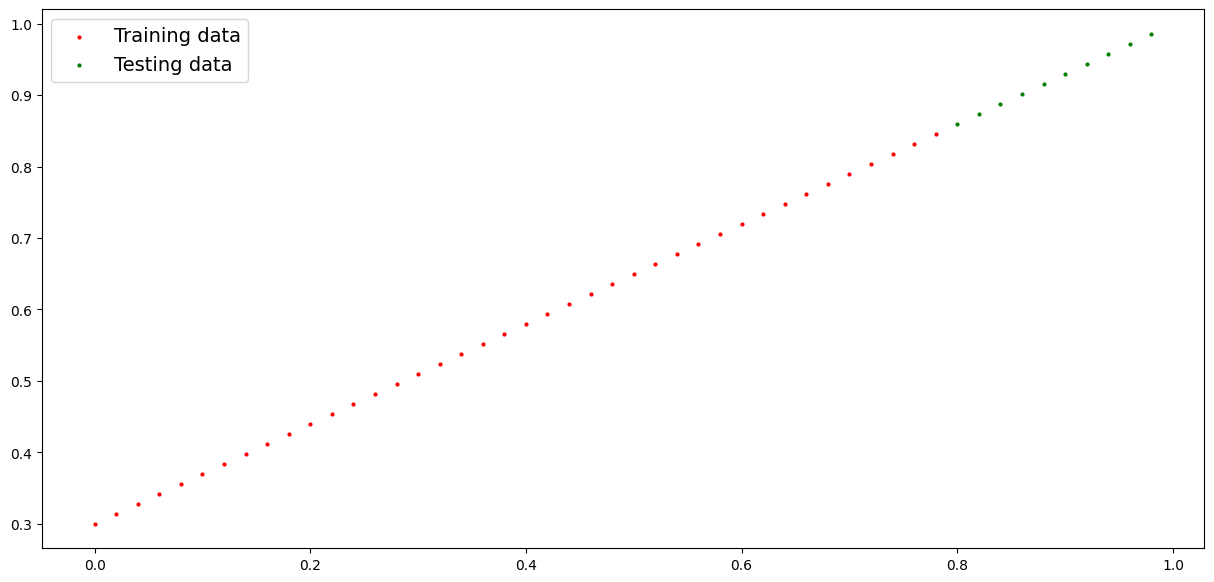

In [73]:
def plot_predictions(train_data=X_train, 
                     train_labels=y_train, 
                     test_data=X_test, 
                     test_labels=y_test, 
                     predictions=None):
    """
    Plots training data, test data and compares predictions.
    """
    plt.figure(figsize=(15, 7))

    # Plot training data in blue
    plt.scatter(train_data, train_labels, c="red", s=4, label="Training data")
    
    # Plot test data in green
    plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

    if predictions is not None:
        # Plot the predictions in red (predictions were made on the test data)
        plt.scatter(test_data, predictions, c="black", s=4, label="Predictions")

    # Show the legend
    plt.legend(prop={"size": 14})
plot_predictions()

### **Train the model**

In [5]:
# Create a Linear Regression model class
class LinearRegressionModel(nn.Module): # <- almost everything in PyTorch is a nn.Module (think of this as neural network lego blocks)
    def __init__(self):
        super().__init__() 
        self.weights = nn.Parameter(torch.randn(1,         # <- start with random weights (this will get adjusted as the model learns)
                                                dtype=torch.float), # <- PyTorch loves float32 by default
                                   requires_grad=True)     # <- can we update this value with gradient descent?)

        self.bias = nn.Parameter(torch.randn(1,            # <- start with random bias (this will get adjusted as the model learns)
                                            dtype=torch.float), # <- PyTorch loves float32 by default
                                requires_grad=True)        # <- can we update this value with gradient descent?))

    # Forward defines the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor:   # <- "x" is the input data (e.g. training/testing features)
        return self.weights * x + self.bias               # <- this is the linear regression formula (y = m*x + b)

In [6]:
# Set manual seed since nn.Parameter are randomly initialized
torch.manual_seed(42)

# Create an instance of the model (this is a subclass of nn.Module that contains nn.Parameter(s))
model_0 = LinearRegressionModel()

# Check the nn.Parameter(s) within the nn.Module subclass we created
(list(model_0.parameters()))

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [7]:
with torch.inference_mode():   #inference for prediction
    predict = model_0(X_test)

# display(predict)
print(len(y_test), len(predict))

10 10


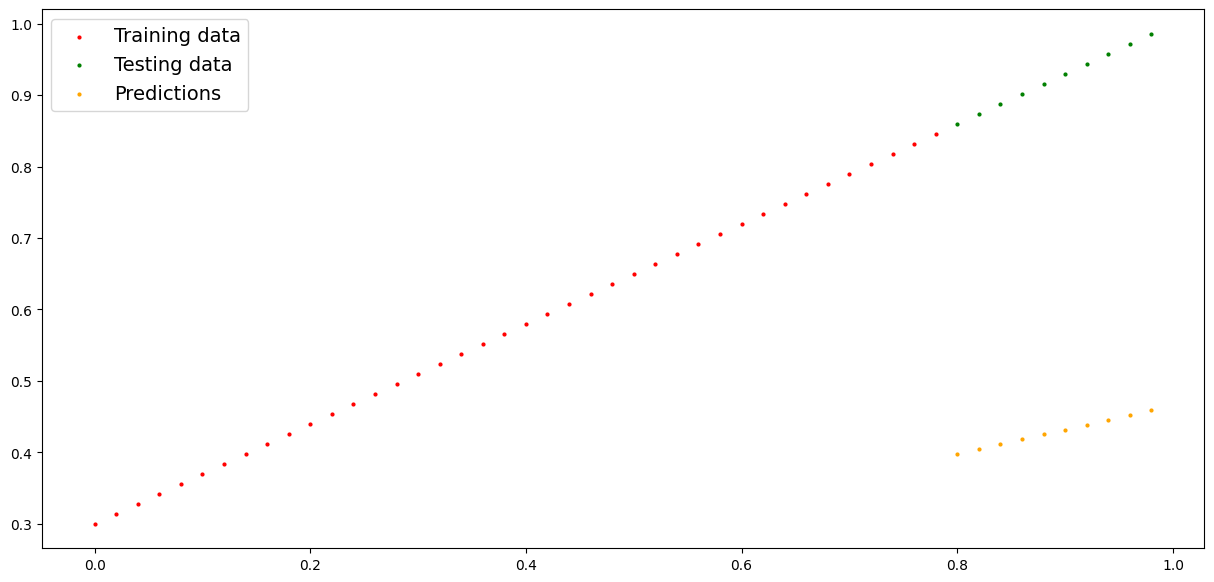

In [8]:
plot_predictions(predictions=predict)

In [9]:
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

In [10]:
optimizer

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [ ]:
torch.manual_seed(42)

epochs = 100
train_loss_values = []
test_loss_values = []
epoch_count = []

loss_fn = torch.nn.L1Loss()

for epoch in range(epochs):
    #pyTorch train loop
    model_0.train()
    y_pred = model_0(X_train)
    loss = loss_fn(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss_values.append(loss.item())
    
    model_0.eval()        #set evaluation mode for prediction. it helps for percistancy and consistancey of the model
    with torch.inference_mode():
        test_pred = model_0(X_test)
        test_loss = loss_fn(test_pred, y_test)
        test_loss_values.append(test_loss.item())
        epoch_count.append(epoch)   

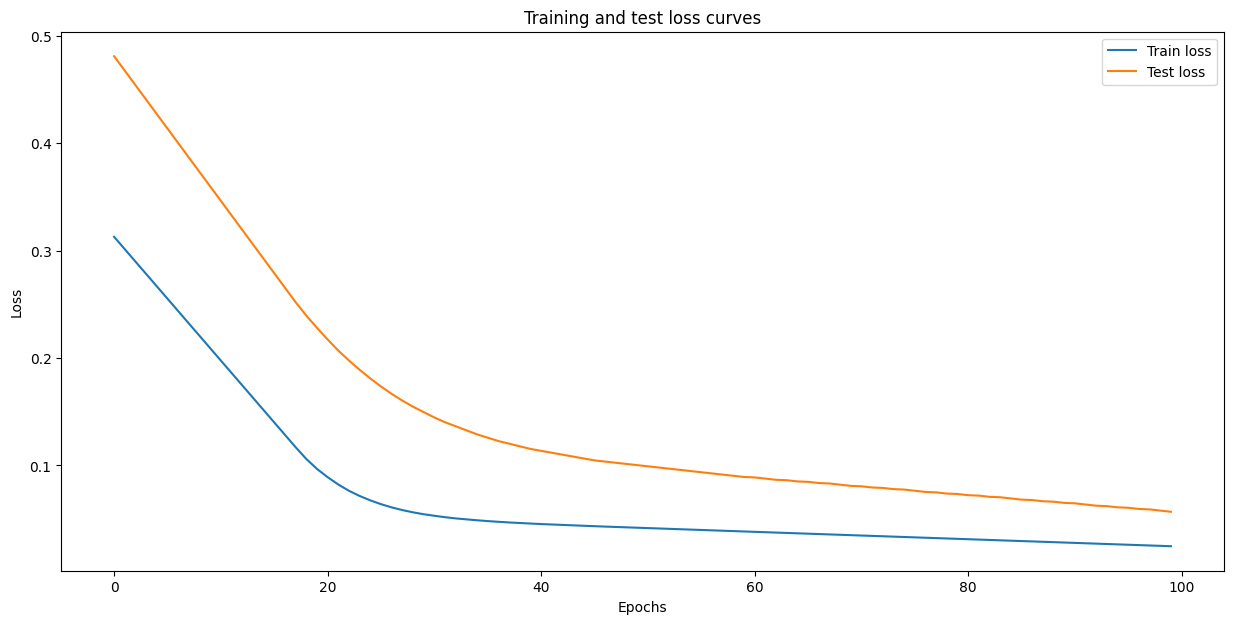

In [15]:
# Plot the loss curves
fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(epoch_count, train_loss_values, label="Train loss")
ax.plot(epoch_count, test_loss_values, label="Test loss")
ax.set_title("Training and test loss curves")
ax.set_ylabel("Loss")
ax.set_xlabel("Epochs")
plt.legend();

In [16]:
# Find our model's learned parameters
print("The model learned the following values for weights and bias:")
print(model_0.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weights': tensor([0.5784]), 'bias': tensor([0.3513])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


In [24]:
#we can predict the prediction using inference
    #set model evaluation mode
    #make prediction using inferece mode  for behind the scense calculation
    #data and object should be only the same device
model_0.eval()
with torch.inference_mode():
    y_prediciton = model_0(X_test)
y_prediciton

tensor([[0.8141],
        [0.8256],
        [0.8372],
        [0.8488],
        [0.8603],
        [0.8719],
        [0.8835],
        [0.8950],
        [0.9066],
        [0.9182]])

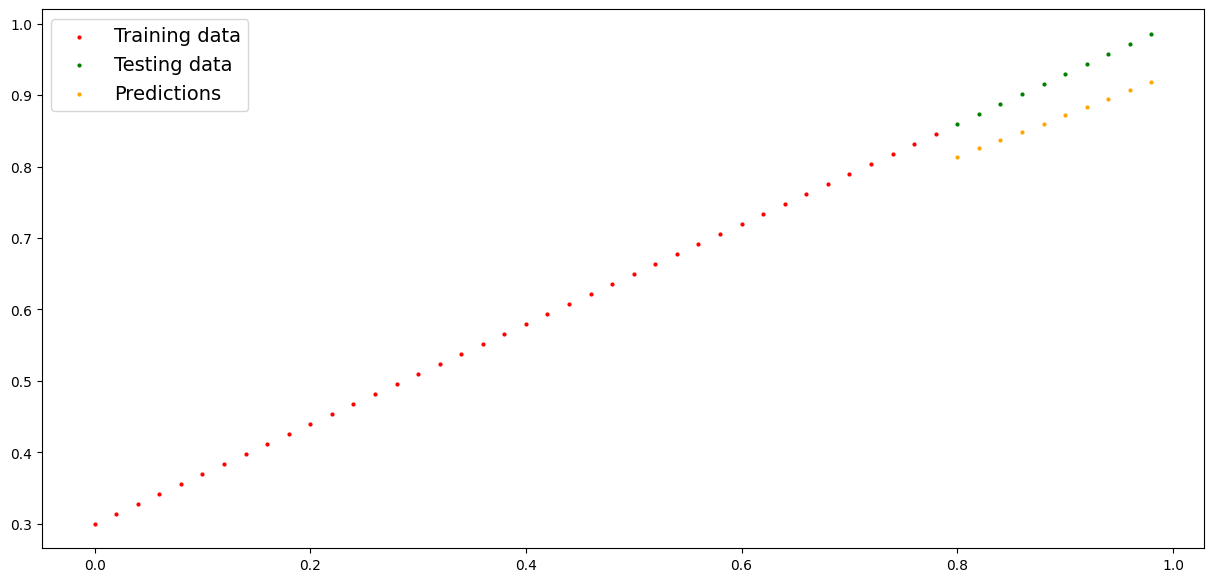

In [25]:
plot_predictions(predictions=y_prediciton)

### **Save and load Models**

**Save the model**

In [30]:
#model, dictionary and tensor can be saved on disc uisng pickl's
# torch.save, torch.load and torch.nn.Module.load_state_dict
from pathlib import Path

model_path = Path("Model")
model_path.mkdir(parents=True, exist_ok=True)  #this make directory(create folder for model)
Model_name = "pyTorch_model.pth"
model_save_path = model_path / Model_name

#save the mdole now
print(f"Saving the model to: {model_save_path}")
torch.save(obj=model_0.state_dict(), f=model_save_path)

Saving the model to: Model/pyTorch_model.pth


In [32]:
!ls -1 Model/pyTorch_model.pth

Model/pyTorch_model.pth


**Load the model dictionary**

In [33]:
linear_model = LinearRegressionModel()  #intialiaze the model object

linear_model.load_state_dict(torch.load(f=model_save_path))

<All keys matched successfully>

In [34]:
linear_model.eval()  #model in evaluation mode

with torch.inference_mode():  #make prediction with inference
    linear_model_prediction = linear_model(X_test)
linear_model_prediction

tensor([[0.8141],
        [0.8256],
        [0.8372],
        [0.8488],
        [0.8603],
        [0.8719],
        [0.8835],
        [0.8950],
        [0.9066],
        [0.9182]])

In [35]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [40]:
# Create weight and bias
weight = 0.7
bias = 0.3

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) # without unsqueeze, errors will happen later on (shapes within linear layers)
y = weight * X + bias 
X[:10], y[:10]
X.shape, y.shape, X.ndim, y.ndim

(torch.Size([50, 1]), torch.Size([50, 1]), 2, 2)

In [63]:
train_split_value = int(len(X) * 0.8)
train_feature , treain_label = X[:train_split_value], y[:train_split_value]
test_feature, test_label = X[train_split_value:], y[train_split_value:]

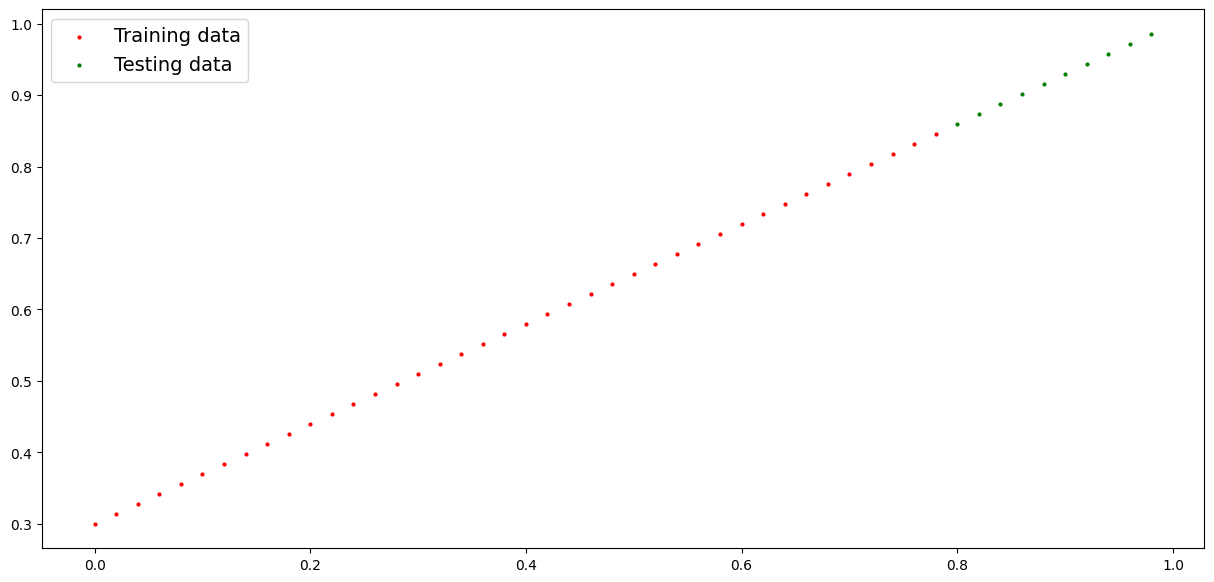

In [64]:
plot_predictions(train_feature, treain_label, test_feature, test_label)

In [50]:
class myLinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        return self.linear_layer(x)

In [ ]:
torch.manual_seed(42)   #it is used for reproducablity purpose
model1 = myLinearModel()
model1, model1.state_dict(), next(model1.parameters()).device #my device is cpu, gpu not avialable in my computer so i can not use other option than cpu

(myLinearModel(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]),
 device(type='cpu'))

In [ ]:
#two things are need 1. calculate loss functin and 2. optimize the paramter
#create loss function
loss_function = nn.L1Loss()

#create optimizer
optimizer_1 = torch.optim.SGD(params=model1.parameters(), lr=0.01)

In [65]:
torch.manual_seed(42)

epoches = 1000

for epoch in range(epoches):
    model1.train()  #train the model
    y_predic = model1(train_feature) #Make prediction on training data
    loss_cal = loss_function(y_predic, treain_label)
    optimizer_1.zero_grad()    #zero out gradients
    loss_cal.backward()        #backpropagate the loss
    optimizer_1.step()         #update the parameters

    #testing the model(testing loop)
    model1.eval()
    with torch.inference_mode():
        test_pred = model1(test_feature)
        test_loss = loss_function(test_pred, test_label)
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss_cal} | Test Loss: {test_loss}")    

Epoch: 0 | Loss: 0.5551779866218567 | Test Loss: 0.5739762187004089
Epoch: 100 | Loss: 0.006215679459273815 | Test Loss: 0.014086711220443249
Epoch: 200 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 300 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 400 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 500 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 600 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 700 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 800 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 900 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904


In [71]:
from pprint import pprint
pprint(model1.state_dict())
print(model1.state_dict())
print(f"weights: {weight}, bias: {bias}")

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])
OrderedDict({'linear_layer.weight': tensor([[0.6968]]), 'linear_layer.bias': tensor([0.3025])})
weights: 0.7, bias: 0.3


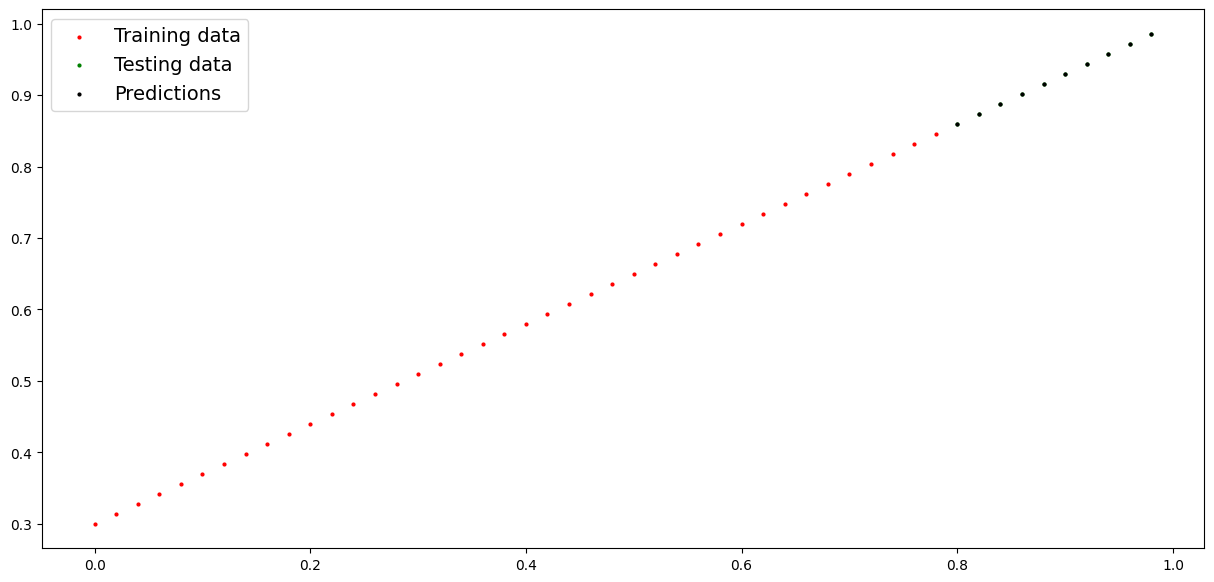

In [74]:
#makeing prediction 
model1.eval()
with torch.inference_mode():
    y_preds = model1(test_feature)
plot_predictions(train_feature, treain_label, test_feature, test_label, y_preds)